# Cue accumulation with e-prop

e-prop (Bellec et al. 2020) approximates the BPTT gradient with information that is local in time. 

The only difference from BPTT in this implementation is that spikes $z_t$ pass no gradient where they enter the next step's reset and recurrent input (`stop_z_gradient=True`), while the gradient through the threshold adaptation is kept. The forward pass is unchanged.

In [1]:
import time
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from snnrl.network import Weights, init_weights, make_network_params
from snnrl.neuron import make_params
from snnrl.supervised import loss_fn, make_evaluate, train_cue_accumulation
from snnrl.tasks import CueAccumulation, sample_batch

In [2]:
N_OUT = 2
RETRAIN = False

SEED = 0

main_key = jax.random.key(SEED)

init_key, train_key, test_key, analysis_key = jax.random.split(main_key, 4)


PATH_BPTT = Path("results/05_bptt.npz")
PATH_EPROP = Path("results/05_eprop.npz")

In [3]:
task = CueAccumulation()

params = {
    "BPTT": make_network_params(make_params(n_lif=50, n_alif=50)),
    "e-prop": make_network_params(make_params(n_lif=50, n_alif=50, stop_z_gradient=True)),
}

In [4]:
def load_results(path):
    saved = np.load(path)
    weights = Weights(**{k[2:]: jnp.asarray(saved[k]) for k in saved.files if k.startswith("w_")})
    history = {k[8:]: saved[k] for k in saved.files if k.startswith("history_")}
    return weights, history


def save_results(path, weights, history):
    path.parent.mkdir(exist_ok=True)
    np.savez(path,
             **{f"w_{k}": np.asarray(v) for k, v in vars(weights).items()},
             **{f"history_{k}": np.array([r.get(k, np.nan) for r in history], dtype=float)
                for k in sorted(set().union(*history))})

## 1. Training

In [5]:
weights0 = init_weights(init_key, task.n_in, N_OUT, params["BPTT"])

In [6]:
for name, path in [("BPTT", PATH_BPTT), ("e-prop", PATH_EPROP)]:
    if RETRAIN or not path.exists():
        t_start = time.time()
        weights, history = train_cue_accumulation(
            train_key, weights0, params[name], task, stop_at_last_stage=False
        )
        print(f"{name}: trained {len(history)} iterations in {time.time() - t_start:.0f} s")
        save_results(path, weights, history)

In [7]:
weights_bptt, history_bptt = load_results(PATH_BPTT)
weights_eprop, history_eprop = load_results(PATH_EPROP)
histories = {"BPTT": history_bptt, "e-prop": history_eprop}
for name, history in histories.items():
    it, n_cues = history["iteration"].astype(int), history["n_cues"].astype(int)
    print(f"{name:6s}: 7 cues reached at iteration {it[n_cues == 7][0]}")

BPTT  : 7 cues reached at iteration 161
e-prop: 7 cues reached at iteration 261


## 2. Comparison

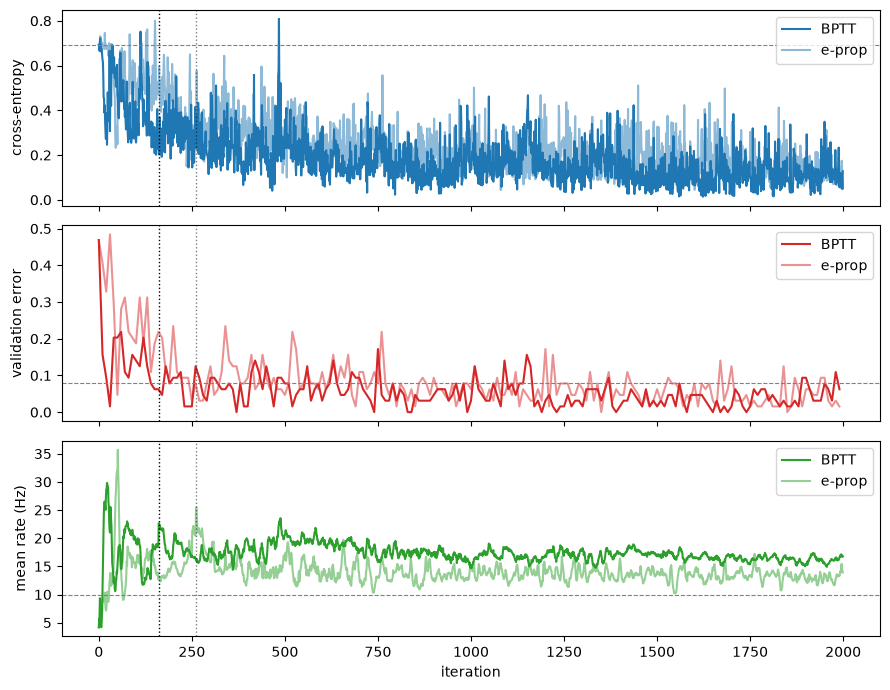

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
for alpha, (name, history) in zip([1, 0.5], histories.items()):
    it, n_cues = history["iteration"].astype(int), history["n_cues"].astype(int)
    validated = ~np.isnan(history["val_error"])
    axes[0].plot(it, history["cross_entropy"], color='C0', alpha=alpha, label=name)
    axes[1].plot(it[validated], history["val_error"][validated], color='C3', alpha=alpha, label=name)
    axes[2].plot(it, history["rate"], color='C2', alpha=alpha, label=name)
    for ax in axes:
        ax.axvline(it[n_cues == 7][0], color='k', ls=":", lw=1, alpha=alpha)
axes[0].axhline(np.log(2), color="gray", ls="--", lw=0.8)
axes[0].set_ylabel("cross-entropy")
for ax in axes: ax.legend(loc="upper right")
axes[1].axhline(0.08, color="gray", ls="--", lw=0.8)
axes[1].set_ylabel("validation error")
axes[2].axhline(10, color="gray", ls="--", lw=0.8)
axes[2].set_ylabel("mean rate (Hz)")
axes[2].set_xlabel("iteration")
fig.tight_layout()

Test

In [9]:
for name, weights in [("BPTT", weights_bptt), ("e-prop", weights_eprop)]:
    evaluate = make_evaluate(params[name], task, batch_size=64, c_reg=1.0, rate_target=10.0)
    errors = [1 - float(evaluate(weights, k, 7)["accuracy"]) for k in jax.random.split(test_key, 32)]
    mean_error = np.mean(errors)
    se_error = np.sqrt(mean_error * (1 - mean_error) / 2048)
    print(f"{name:6s}: test error: {mean_error:.3f} ± {se_error:.3f}")

BPTT  : test error: 0.033 ± 0.004
e-prop: test error: 0.035 ± 0.004


## 3. Gradient alignment

Cosine similarity between the e-prop and BPTT gradients of the training loss, for the input and recurrent weights, on 8 batches of 64 trials with 7 cues. 

The readout weights get identical gradients from both rules.

Compared on the initial weights and the weights trained with BPTT and e-prop.

initial         : w_in 0.79 ± 0.04, w_rec 0.81 ± 0.03
trained (BPTT)  : w_in 0.65 ± 0.19, w_rec 0.63 ± 0.17
trained (e-prop): w_in 0.85 ± 0.02, w_rec 0.82 ± 0.04


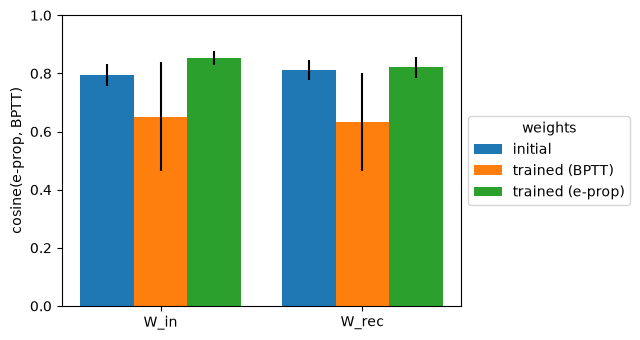

In [10]:
def gradient(weights, x, label, params):
    return jax.grad(loss_fn, has_aux=True)(
        weights, x, label, params, task, c_reg=1.0, rate_target=10.0)[0]

def cosine(a, b):
    return float(jnp.vdot(a, b) / (jnp.linalg.norm(a) * jnp.linalg.norm(b)))


alignment = {}
for name, weights in [("initial", weights0), ("trained (BPTT)", weights_bptt), ("trained (e-prop)", weights_eprop)]:
    values = {"w_in": [], "w_rec": []}
    for key in jax.random.split(analysis_key, 8):
        x, label = sample_batch(key, batch_size=64, n_cues=7, task=task)
        g_bptt = gradient(weights, x, label, params["BPTT"])
        g_eprop = gradient(weights, x, label, params["e-prop"])
        for k in values:
            values[k].append(
                cosine(getattr(g_bptt, k), getattr(g_eprop, k))
            )
    alignment[name] = values
    print(f"{name:16s}: " + ", ".join(f"{k} {np.mean(v):.2f} ± {np.std(v):.2f}" for k, v in values.items()))

# One group of bars per weight matrix, one bar per set of weights
width = 0.8 / len(alignment)
fig, ax = plt.subplots(figsize=(6.5, 3.5))
for i, (name, values) in enumerate(alignment.items()):
    offset = (i - (len(alignment) - 1) / 2) * width
    for j, k in enumerate(values):
        ax.bar(j + offset, np.mean(values[k]), width=width, yerr=np.std(values[k]),
               color=f"C{i}", label=name if j == 0 else None)
ax.set_xticks([0, 1], ["W_in", "W_rec"])
ax.set_ylim(0, 1)
ax.set_ylabel("cosine(e-prop, BPTT)")
ax.legend(title="weights", loc="center left", bbox_to_anchor=(1, 0.5))
fig.tight_layout()